# 1. Generate and clean Nairobi rent data

This notebook builds an illustrative sample of rental listings for Nairobi neighbourhoods (Kasarani, Kayole, Kileleshwa, Kitengela, Muthaiga and Runda), stores it in `data/rent.csv`, selects the fields used by the app, removes invalid rows and outliers, and writes `data/clean_rent.csv` for the training notebook. Rents are monthly amounts in Kenya shillings (KES).

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data"

rng = np.random.default_rng(42)
AREAS = {
    "Kasarani": {"base": 15000, "size_per_bed": 400, "beds": [1, 2, 3, 4], "weights": [0.20, 0.45, 0.28, 0.07], "furnishing": [0.50, 0.35, 0.15]},
    "Kayole": {"base": 9000, "size_per_bed": 320, "beds": [1, 2, 3], "weights": [0.35, 0.50, 0.15], "furnishing": [0.60, 0.30, 0.10]},
    "Kileleshwa": {"base": 38000, "size_per_bed": 420, "beds": [1, 2, 3, 4], "weights": [0.20, 0.45, 0.27, 0.08], "furnishing": [0.25, 0.35, 0.40]},
    "Kitengela": {"base": 12000, "size_per_bed": 380, "beds": [1, 2, 3, 4], "weights": [0.25, 0.45, 0.25, 0.05], "furnishing": [0.55, 0.35, 0.10]},
    "Muthaiga": {"base": 140000, "size_per_bed": 700, "beds": [2, 3, 4, 5], "weights": [0.18, 0.38, 0.32, 0.12], "furnishing": [0.20, 0.30, 0.50]},
    "Runda": {"base": 110000, "size_per_bed": 650, "beds": [2, 3, 4, 5], "weights": [0.20, 0.40, 0.30, 0.10], "furnishing": [0.20, 0.30, 0.50]},
}
BEDROOM_FACTOR = {1: 0.75, 2: 1.0, 3: 1.45, 4: 2.0, 5: 2.6}
FURNISHING = ["Unfurnished", "Semi-Furnished", "Furnished"]
FURNISHING_FACTOR = {"Unfurnished": 1.0, "Semi-Furnished": 1.08, "Furnished": 1.16}

rows = []
for area, profile in AREAS.items():
    for _ in range(850):
        bedrooms = int(rng.choice(profile["beds"], p=profile["weights"]))
        furnishing = str(rng.choice(FURNISHING, p=profile["furnishing"]))
        typical_size = bedrooms * profile["size_per_bed"]
        size = int(round(np.clip(typical_size * rng.lognormal(0, 0.18), 250, 6000) / 10) * 10)
        size_factor = (size / typical_size) ** 0.7
        rent = (
            profile["base"]
            * BEDROOM_FACTOR[bedrooms]
            * size_factor
            * FURNISHING_FACTOR[furnishing]
            * rng.lognormal(0, 0.18)
        )
        posted = pd.Timestamp("2025-01-01") + pd.to_timedelta(int(rng.integers(0, 670)), unit="D")
        rows.append(
            {
                "Posted On": posted.date().isoformat(),
                "BHK": bedrooms,
                "Rent": int(round(rent / 500) * 500),
                "Size": size,
                "Floor": str(rng.choice(["Ground out of 2", "1 out of 3", "2 out of 5", "3 out of 7"])),
                "Area Type": str(rng.choice(["Super Area", "Carpet Area"])),
                "Area Locality": area,
                "Area": area,
                "Furnishing Status": furnishing,
                "Tenant Preferred": str(rng.choice(["Family", "Bachelors", "Bachelors/Family"])),
                "Bathroom": max(1, bedrooms - 1),
                "Point of Contact": str(rng.choice(["Contact Owner", "Contact Agent"])),
            }
        )

raw = pd.DataFrame(rows)
raw.to_csv(DATA_DIR / "rent.csv", index=False)
print("Raw shape:", raw.shape)
raw.head()

Raw shape: (5100, 12)


,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,Area,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2025-05-15,3,28500,1370,Ground out of 2,Carpet Area,Kasarani,Kasarani,Unfurnished,Bachelors/Family,2,Contact Agent
1,2026-05-25,3,23000,1030,Ground out of 2,Carpet Area,Kasarani,Kasarani,Unfurnished,Bachelors/Family,2,Contact Agent
2,2026-08-18,3,21000,1030,Ground out of 2,Carpet Area,Kasarani,Kasarani,Unfurnished,Bachelors/Family,2,Contact Owner
3,2026-02-28,3,24500,1500,2 out of 5,Carpet Area,Kasarani,Kasarani,Unfurnished,Bachelors/Family,2,Contact Owner
4,2026-09-11,2,17000,860,2 out of 5,Super Area,Kasarani,Kasarani,Unfurnished,Bachelors/Family,1,Contact Owner


In [2]:
renamed = raw.rename(columns={"BHK": "bedrooms", "Rent": "rent", "Size": "size", "Area": "city", "Furnishing Status": "furnishing"})
df = renamed[["bedrooms", "size", "city", "furnishing", "rent"]].copy()
print(df.dtypes)
print("Missing values:")
print(df.isna().sum())
df.describe(include="all")

bedrooms      int64
size          int64
city            str
furnishing      str
rent          int64
dtype: object
Missing values:
bedrooms      0
size          0
city          0
furnishing    0
rent          0
dtype: int64


,bedrooms,size,city,furnishing,rent
count,5100.000000,5100.000000,5100,5100,5100.000000
unique,NaN,NaN,6,3,NaN
top,NaN,NaN,Kasarani,Unfurnished,NaN
freq,NaN,NaN,850,1954,NaN
mean,2.493137,1300.629412,NaN,NaN,93701.666667
std,1.032209,875.006747,NaN,NaN,114746.475523
min,1.000000,250.000000,NaN,NaN,3500.000000
25%,2.000000,660.000000,NaN,NaN,12500.000000
50%,2.000000,1030.000000,NaN,NaN,29000.000000
75%,3.000000,1802.500000,NaN,NaN,168000.000000


In [3]:
for column in ["bedrooms", "size", "rent"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

df["city"] = df["city"].astype("string").str.strip()
df["furnishing"] = df["furnishing"].astype("string").str.strip()
df = df.dropna()
df = df[(df["bedrooms"] > 0) & (df["bedrooms"] <= 10) & (df["size"] > 100) & (df["rent"] > 0)]

lower = df[["size", "rent"]].quantile(0.01)
upper = df[["size", "rent"]].quantile(0.99)
df = df[(df["size"] >= lower["size"]) & (df["size"] <= upper["size"])]
df = df[(df["rent"] >= lower["rent"]) & (df["rent"] <= upper["rent"])]
df = df.reset_index(drop=True)

print("Clean shape:", df.shape)
print("Areas:", sorted(df["city"].unique()))
print("Furnishing:", sorted(df["furnishing"].unique()))
df.head()

Clean shape: (4963, 5)
Areas: ['Kasarani', 'Kayole', 'Kileleshwa', 'Kitengela', 'Muthaiga', 'Runda']
Furnishing: ['Furnished', 'Semi-Furnished', 'Unfurnished']


,bedrooms,size,city,furnishing,rent
0,3,1370,Kasarani,Unfurnished,28500
1,3,1030,Kasarani,Unfurnished,23000
2,3,1030,Kasarani,Unfurnished,21000
3,3,1500,Kasarani,Unfurnished,24500
4,2,860,Kasarani,Unfurnished,17000


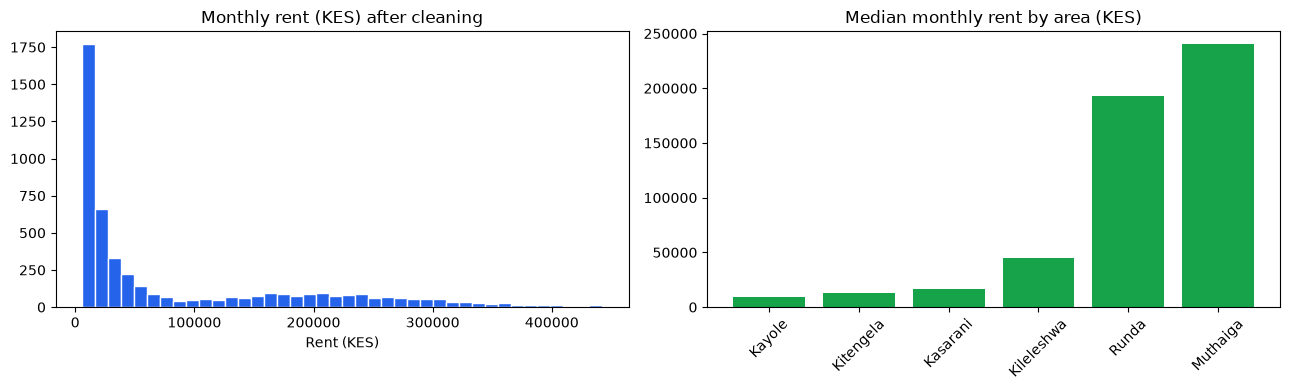

In [4]:
median_rent = df.groupby("city")["rent"].median().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(df["rent"], bins=40, color="#2563eb", edgecolor="white")
axes[0].set_title("Monthly rent (KES) after cleaning")
axes[0].set_xlabel("Rent (KES)")
axes[1].bar(median_rent.index, median_rent.values, color="#16a34a")
axes[1].set_title("Median monthly rent by area (KES)")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [5]:
clean_path = DATA_DIR / "clean_rent.csv"
df.to_csv(clean_path, index=False)
print(f"Saved {len(df)} rows to {clean_path}")

Saved 4963 rows to /home/dengdit/house-rent-predictor/data/clean_rent.csv
